### Langchain version v1

In [3]:
1+5

6

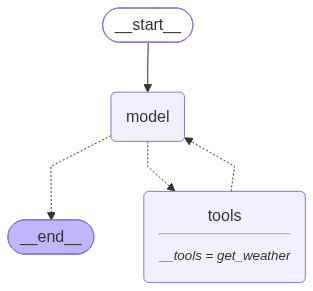

In [17]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

from langchain_ollama import ChatOllama
from langchain.agents import create_agent
from IPython.display import Image, display

llm = ChatOllama(
    model="gpt-oss:120b",
    base_url="https://ollama.com",   # no /api at the end
    client_kwargs={"headers": {"Authorization": f"Bearer {os.getenv('OLLAMA_API_KEY')}"}},
)
def get_weather(city:str)->str:
    """Get the weather of a city."""
    return f"The weather of a {city} is sunny."

agent = create_agent(
    model=llm, 
    tools=[get_weather], 
    system_prompt="You are a helpful assistant."
)
display(Image(agent.get_graph().draw_mermaid_png()))

In [8]:
result = agent.invoke(
    {"messages": [{"role": "user", "content": "What is the weather like in Bengaluru?"}]}
)
print(result["messages"][-1].content)

The weather in Bengaluru is currently **sunny**. Enjoy your day!


In [13]:
for chunk in llm.stream("Write a 200 words paragraph on Artificial Intelligence."):
    print(chunk.text, end="", flush=True)


Artificial intelligence (AI) is a multidisciplinary field that seeks to create machines capable of performing tasks traditionally requiring human cognition, such as perception, reasoning, learning, and decision‑making. Rooted in computer science, mathematics, neuroscience, and philosophy, modern AI blends symbolic approaches with statistical methods, enabling systems to process massive data sets, recognize patterns, and adapt through machine learning algorithms like deep neural networks. These technologies have transformed industries: autonomous vehicles interpret sensor inputs to navigate complex environments, medical diagnostics employ image‑analysis models to detect subtle disease markers, and natural‑language interfaces translate human speech into actionable commands, reshaping communication. Yet AI also raises profound ethical and societal challenges, including bias amplification, privacy erosion, and the potential displacement of labor. Researchers advocate for transparent, accou

In [16]:
responses = llm.batch([
    "Why do parrot have colourful feathers?",
    "How airplanes fly?",
    "What is quantam computing?"
],
config = {
    "max_concurrency": 5,
}
)
for response in responses:
    print(response.content, end="\n", flush=True)

**Short answer:**  
Parrots are colorful because their bright feathers serve several biological purposes—mainly **communication and attraction** (for mates, rivals, and group members), **species‑recognition**, **signaling health**, and sometimes **camouflage or warning**. The colors are produced by a mix of pigments (carotenoids and melanins) and microscopic feather structures that scatter light (structural colors). Natural and sexual selection have kept these vivid patterns in the bird family.

---

## 1. How the colors are made  

| Type of color | Source | Typical hue | How it works |
|---|---|---|---|
| **Carotenoid pigments** | Diet (fruits, seeds, nectar, insects) | Reds, oranges, yellows | Birds cannot synthesize carotenoids; they must eat them and deposit them in feathers. The brighter the deposit, the more vibrant the hue. |
| **Melanin pigments** | Synthesized from the amino acid tyrosine | Blacks, browns, grays | Gives durability and UV‑resistance; can be mixed with other pi